In [ ]:
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

from src import xp
from src.surrogate import NearODESurrogate

/home/prajwal/github-repos/knnsur/src/__init__.py:18: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
# ==========================================
# 1. Physics: Parameterized Logistic Equation
# ==========================================
# ODE: dx/dt = r * x * (1 - x)
# We treat the system inputs as X = [x, r]
# x: Population (state)
# r: Growth rate (parameter, constant during flow)
DT = 0.5  # Time step


def logistic_deriv(t, X_aug):
    """
    Computes the augmented dynamics for state and sensitivities.
    X_aug vector structure: [x, s_x, s_r]
      x:   Current population
      s_x: Sensitivity dx(t)/dx_0
      s_r: Sensitivity dx(t)/dr
    """
    x = X_aug[0]
    s_x = X_aug[1]
    s_r = X_aug[2]

    # We need 'r' but it's not in X_aug (it's constant).
    # We pass it via closure or global. Using global for script simplicity.
    # ideally this is passed as 'args' in solve_ivp.
    r = CURRENT_R_BATCH_VAL

    # 1. Physics: dx/dt = rx(1-x)
    dx = r * x * (1 - x)

    # 2. Variational Equations
    # df/dx = r - 2rx
    # df/dr = x(1-x)
    df_dx = r - 2 * r * x
    df_dr = x * (1 - x)

    # ds_x/dt = (df/dx) * s_x
    d_sx = df_dx * s_x

    # ds_r/dt = (df/dx) * s_r + df/dr
    d_sr = df_dx * s_r + df_dr

    return np.array([dx, d_sx, d_sr])


# ==========================================
# 2. Integration: Flow Map & Gradients
# ==========================================
# Global placeholder for the current 'r' being integrated
CURRENT_R_BATCH_VAL = 1.0


def compute_flow_and_grads(X_input_batch, dt):
    """
    Integrates batch of inputs [x0, r] forward by dt.
    Returns:
        F: (N, 1) -> Next Population
        G: (N, 1, 2) -> Gradient [dNext/dx0, dNext/dr]
    """
    N, D = X_input_batch.shape  # D=2 (x, r)
    F = np.zeros((N, 1))
    G = np.zeros((N, 1, 2))

    for i in range(N):
        x0 = X_input_batch[i, 0]
        r0 = X_input_batch[i, 1]

        # Set global for the ODE function
        global CURRENT_R_BATCH_VAL
        CURRENT_R_BATCH_VAL = r0

        # Initial Augmented State: [x0, 1.0, 0.0]
        # s_x(0) = 1 (dx/dx = 1)
        # s_r(0) = 0 (dx/dr = 0 at t=0)
        Z0 = np.array([x0, 1.0, 0.0])

        sol = solve_ivp(logistic_deriv, [0, dt], Z0, t_eval=[dt], method="RK45")

        final_vec = sol.y[:, -1]
        x_next = final_vec[0]
        sx_next = final_vec[1]
        sr_next = final_vec[2]

        # Output F
        F[i, 0] = x_next

        # Output Jacobian Row: [dx_next/dx0, dx_next/dr]
        G[i, 0, 0] = sx_next
        G[i, 0, 1] = sr_next

    return F, G


# Wrapper for the surrogate
def f_logistic(X):
    F, _ = compute_flow_and_grads(X, DT)
    return F  # (N, 1)


def g_logistic(X):
    _, G = compute_flow_and_grads(X, DT)
    return G  # (N, 1, 2)

In [ ]:
# ------------------------------------------------
# A. Generate Random Inputs (x, r)
# ------------------------------------------------
# x domain: [0.1, 1.2] (Avoid 0 to keep dynamics interesting)
# r domain: [0.5, 3.5] (From decay to chaotic-ish growth)
X_MIN, X_MAX = 0.1, 1.2
R_MIN, R_MAX = 0.5, 3.5

N_TRAIN = 1000
TOL = 1e-3

print(f"1. Sampling {N_TRAIN} points in x=[{X_MIN},{X_MAX}], r=[{R_MIN},{R_MAX}]...")

x_train = np.random.uniform(X_MIN, X_MAX, N_TRAIN)
r_train = np.random.uniform(R_MIN, R_MAX, N_TRAIN)
X_train = np.column_stack([x_train, r_train])

# ------------------------------------------------
# B. Train Surrogate (R^2 -> R^1)
# ------------------------------------------------
print(f"2. Training Surrogate on Logistic Flow Map...")

model = NearODESurrogate(version="v2")
model.train(
    X_train=xp.asarray(X_train),
    f_fn=f_logistic,
    g_fn=g_logistic,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=10,
    MIN_PTS_PER_CLUSTER=20,
    MAX_CLUSTERS_EST=200,
    SEED=42,
    ERROR_METRIC="Linf-global",
)
n_clusters = model.get_number_of_sources()
print(f"   Model Trained. # Clusters: {n_clusters}")

1. Sampling 1000 points in x=[0.1,1.2], r=[0.5,3.5]...
2. Training Surrogate on Logistic Flow Map...
   Model Trained. # Clusters: 151


3. Evaluating Error on (x, r) Grid...
----------------------------------------
LOGISTIC EQUATION (R^2 -> R^1) METRICS
N_TRAIN: 1000, TOL: 0.001, DT: 0.5, N_TEST: 2500, K_NN: 100
----------------------------------------
Trust Region Coverage:    84.40% (2110 points)
----------------------------------------
L2 Relative Error:       1.271456e-03
L2 Absolute Error:       1.025683e-03
Max Rel Error:           3.532333e-02
Median Rel Error:        3.467171e-04
----------------------------------------
4. Plotting...


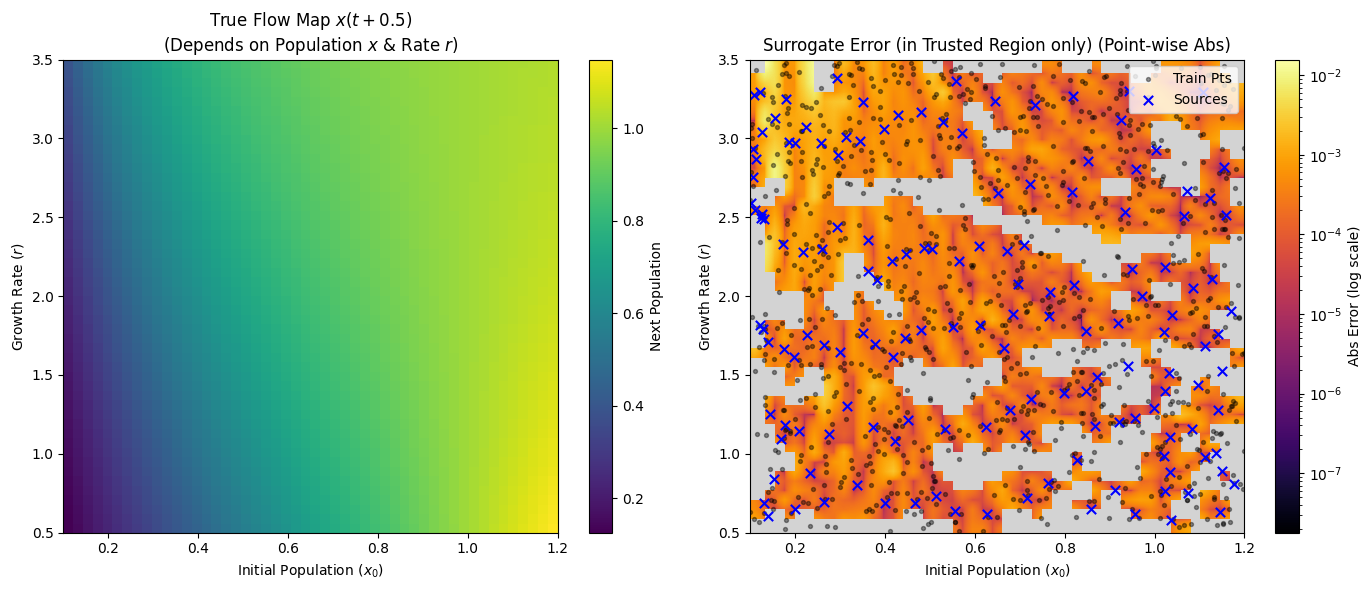

In [11]:
# ------------------------------------------------
# C. Test on Grid (Parameter Sweep)
# ------------------------------------------------
print("3. Evaluating Error on (x, r) Grid...")

grid_res = 50
K_NN = 100
x_vals = np.linspace(X_MIN, X_MAX, grid_res)
r_vals = np.linspace(R_MIN, R_MAX, grid_res)
XX, RR = np.meshgrid(x_vals, r_vals)
X_test_grid = np.column_stack([XX.ravel(), RR.ravel()])
N_TEST = X_test_grid.shape[0]

# 1. Ground Truth
Y_true, _ = compute_flow_and_grads(X_test_grid, DT)

# 2. Surrogate Prediction
inp = xp.asarray(X_test_grid)
Y_pred_raw, mask_raw = model.predict(inp, k_NEIGHBOURS=K_NN)

# Reshape / Flatten
Y_pred = np.array(Y_pred_raw).reshape(-1, 1)
unguaranteed_mask = np.array(mask_raw).flatten()

# 3. Compute Metrics
errors = np.abs(Y_true - Y_pred).flatten()

g_idx = ~unguaranteed_mask
n_in = np.sum(g_idx)
n_out = np.sum(unguaranteed_mask)
perct_out = 100.0 * n_out / N_TEST

if n_in > 0:
    Y_true_valid = Y_true[g_idx]
    Y_pred_valid = Y_pred[g_idx]

    # L2 Absolute Error
    numer_l2 = np.linalg.norm(Y_true_valid - Y_pred_valid)
    l2_abs_error = numer_l2 / np.sqrt(n_in)

    # L2 Relative Error
    TINY_EPS = 1e-8
    denom_l2 = np.linalg.norm(Y_true_valid) + TINY_EPS
    l2_rel_error = numer_l2 / denom_l2

    # Pointwise Relative Error
    diff = np.abs(Y_true_valid - Y_pred_valid)
    norm_true = np.abs(Y_true_valid) + TINY_EPS
    ptwise_rel_error = diff / norm_true

    max_rel_error = np.max(ptwise_rel_error)
    median_rel_error = np.median(ptwise_rel_error)
else:
    l2_abs_error = np.nan
    l2_rel_error = np.nan
    max_rel_error = np.nan
    median_rel_error = np.nan

# 4. Print Report
print("-" * 40)
print("LOGISTIC EQUATION (R^2 -> R^1) METRICS")
print(f"N_TRAIN: {N_TRAIN}, TOL: {TOL}, DT: {DT}, N_TEST: {N_TEST}, K_NN: {K_NN}")
print("-" * 40)
print(f"Trust Region Coverage:   {100 - perct_out:6.2f}% ({n_in} points)")
print("-" * 40)
if n_in > 0:
    print(f"L2 Relative Error:       {l2_rel_error:.6e}")
    print(f"L2 Absolute Error:       {l2_abs_error:.6e}")
    print(f"Max Rel Error:           {max_rel_error:.6e}")
    print(f"Median Rel Error:        {median_rel_error:.6e}")
print("-" * 40)

# ------------------------------------------------
# D. Visualization
# ------------------------------------------------
print("4. Plotting...")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: The Function Landscape (True Next Population)
Y_grid = Y_true.reshape(grid_res, grid_res)

c1 = ax[0].imshow(
    Y_grid,
    extent=[X_MIN, X_MAX, R_MIN, R_MAX],
    origin="lower",
    cmap="viridis",
    aspect="auto",
)
ax[0].set_title(f"True Flow Map $x(t+{DT})$\n(Depends on Population $x$ & Rate $r$)")
ax[0].set_xlabel("Initial Population ($x_0$)")
ax[0].set_ylabel("Growth Rate ($r$)")
fig.colorbar(c1, ax=ax[0], label="Next Population")

# Plot 2: Surrogate Error Heatmap
err_grid = errors.reshape(grid_res, grid_res)
mask_grid = unguaranteed_mask.reshape(grid_res, grid_res)
err_grid_masked = np.ma.masked_where(mask_grid, err_grid)

centroids = model.X_src
ax[1].scatter(X_train[:, 0], X_train[:, 1], c="k", s=8, alpha=0.4, label="Train Pts")
ax[1].scatter(
    centroids[:, 0], centroids[:, 1], c="b", s=45, marker="x", label="Sources"
)
ax[1].set_facecolor("lightgrey")

# Log scale handling for error plot
valid_errors = (
    err_grid_masked[~err_grid_masked.mask]
    if np.ma.is_masked(err_grid_masked)
    else err_grid_masked
)
if len(valid_errors) > 0 and np.max(valid_errors) > 0:
    vmin = max(np.min(valid_errors[valid_errors > 0]), 1e-10)
    vmax = np.max(valid_errors)
    norm = colors.LogNorm(vmin=vmin, vmax=vmax)
else:
    norm = None

c2 = ax[1].imshow(
    err_grid_masked,
    extent=[X_MIN, X_MAX, R_MIN, R_MAX],
    origin="lower",
    cmap="inferno",
    aspect="auto",
    norm=norm,
    interpolation="bilinear",
)

ax[1].set_title("Surrogate Error (in Trusted Region only) (Point-wise Abs)")
ax[1].set_xlabel("Initial Population ($x_0$)")
ax[1].set_ylabel("Growth Rate ($r$)")
fig.colorbar(c2, ax=ax[1], label="Abs Error (log scale)")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()